## 5-8_ROC_Analysis

In [3]:
## 1. Load the dataset, train logistic regression, and predict probabilities.

import pandas as pd

data_web_address = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"
column_names = ['pregnancy_x', 
                'plasma_con', 
                'blood_pressure', 
                'skin_mm', 
                'insulin', 
                'bmi', 
                'pedigree_func', 
                'age', 
                'target']

feature_names = column_names[:-1]
all_data = pd.read_csv(data_web_address , names=column_names)
all_data.head()


import numpy as np
import pandas as pd

X = all_data[feature_names]
y = all_data['target']


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7,stratify=y)

from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train,y_train)

y_pred = lr.predict(X_test)
y_pred_proba = lr.predict_proba(X_test)
y_pred_proba[:,1]


e:\ML\ML-Engineering-Lab\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


array([0.09415501, 0.10551391, 0.1221182 , 0.17615761, 0.17829857,
       0.00628421, 0.05394899, 0.27989174, 0.08406309, 0.56827609,
       0.18961981, 0.6275725 , 0.17236429, 0.17292428, 0.80452857,
       0.05152188, 0.52274597, 0.20774696, 0.25581345, 0.01751282,
       0.71739169, 0.69236332, 0.27674308, 0.3089773 , 0.75733174,
       0.26996813, 0.29363157, 0.06714361, 0.14196694, 0.86000757,
       0.83484686, 0.63304287, 0.14356988, 0.40791353, 0.71098176,
       0.07657907, 0.13040103, 0.82337244, 0.29169995, 0.36940444,
       0.3413319 , 0.10921458, 0.10857376, 0.05877354, 0.10396504,
       0.22935666, 0.29055467, 0.57609017, 0.07716743, 0.13204991,
       0.384603  , 0.5030355 , 0.23075767, 0.25736703, 0.13767995,
       0.0607474 , 0.66509809, 0.050887  , 0.18539615, 0.1382756 ,
       0.66732026, 0.19217866, 0.47018379, 0.01276782, 0.10058703,
       0.34384098, 0.43047612, 0.68346737, 0.24492866, 0.58935791,
       0.65318115, 0.20211567, 0.25156598, 0.73252398, 0.19840

In [4]:
## 2. Calculate the ROC curve values.

from sklearn.metrics import roc_curve

fpr, tpr, ths = roc_curve(y_test, y_pred_proba[:,1])

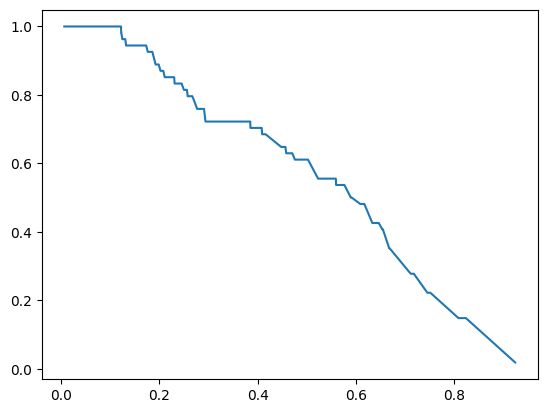

In [5]:
## 3. Plot the true positive rate against classification thresholds.

import matplotlib.pyplot as plt
%matplotlib inline

plt.plot(ths,tpr)

In [6]:
## 4. Evaluate predictions using a classification threshold of 0.1.

from sklearn.preprocessing import binarize
from sklearn.metrics import confusion_matrix
y_pred_th= binarize(y_pred_proba, threshold=0.1)
confusion_matrix(y_test, y_pred_th[:,1],labels=[1,0])

array([[54,  0],
       [67, 33]])

In [7]:
## 5. Evaluate predictions using a classification threshold of 0.146.

y_pred_th = binarize(y_pred_proba, threshold=0.146)
confusion_matrix(y_test, y_pred_th[:,1],labels=[1,0])

array([[51,  3],
       [49, 51]])